# Analysing Customer Reviews using NLP
### From Text to Insight

In this assignment, I am analysing Amazon Beauty product reviews to understand what customers talk about and how they feel about the products.

I will clean the reviews, extract named entities, create text representations, find topics using LDA and train models to classify positive and negative reviews.

The dataset has two columns:
- `review_text`: customer review
- `sentiment`: 1 for positive and 0 for negative

I am using two separate text streams:
- **POS-filtered stream:** only nouns and adjectives, with lemmatisation. This will be used for TF-IDF and LDA.
- **Lightly cleaned stream:** all useful words after removing stopwords, without POS filtering. This will be used for Word2Vec.

## 1. Import libraries

In [39]:
import re
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import spacy

from collections import Counter
from wordcloud import WordCloud

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.decomposition import TruncatedSVD, PCA
from sklearn.naive_bayes import MultinomialNB, BernoulliNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, classification_report,
    ConfusionMatrixDisplay
)

from gensim.models import Word2Vec, LdaModel
from gensim.corpora import Dictionary
from gensim.models import CoherenceModel

RANDOM_STATE = 42

## 3. Load and check the dataset

In [40]:
# Keep the CSV file in the same folder as this notebook
df = pd.read_csv("beauty_reviews_NLP B02 - beauty_reviews.csv")

print("Dataset shape:", df.shape)
display(df.head())
print("\\nMissing values:\\n", df.isnull().sum())
print("\\nSentiment counts:\\n", df["sentiment"].value_counts())

Dataset shape: (8000, 2)


,review_text,sentiment
0,It's not soft enough for baby's,0
1,These fit like a hat rather than something I c...,0
2,Poorly made/manufactured basically started fal...,0
3,I have oily acne prone skin and these don't b...,0
4,Inferior quality. Scratchy. Thin. Don’t remove...,0


\nMissing values:\n review_text    10
sentiment       0
dtype: int64
\nSentiment counts:\n sentiment
0    4000
1    4000
Name: count, dtype: int64


## 4. Clean the dataset

In [41]:
def clean_dataset(data):
    data = data.dropna(subset=["review_text", "sentiment"]).copy()
    data["review_text"] = data["review_text"].astype(str).str.strip()
    data["sentiment"] = data["sentiment"].astype(int)

    data = data[data["review_text"] != ""]
    data = data[data["sentiment"].isin([0, 1])]
    data = data.drop_duplicates(subset=["review_text", "sentiment"])

    return data.reset_index(drop=True)


df = clean_dataset(df)

print("Dataset after cleaning:", df.shape)
print(df["sentiment"].value_counts())

Dataset after cleaning: (7860, 2)
sentiment
0    3981
1    3879
Name: count, dtype: int64


## 5. Load spaCy and create two token streams

I am using `en_core_web_lg` as required.

For each review, I create:
- `pos_tokens`: lemmatised nouns and adjectives for TF-IDF and LDA.
- `w2v_tokens`: all useful non-stopword tokens for Word2Vec, without a POS filter.

NER is also applied to the original review text, before filtering the tokens.

In [42]:
nlp = spacy.load("en_core_web_lg")

def preprocess_reviews(data, nlp):
    pos_tokens_list = []
    w2v_tokens_list = []
    entity_list = []

    texts = data["review_text"].tolist()

    for doc in nlp.pipe(texts, batch_size=64):
        pos_tokens = []
        w2v_tokens = []

        for token in doc:
            if token.is_space or token.is_punct or token.is_stop:
                continue

            if token.is_alpha:
                lemma = token.lemma_.lower().strip()

                if lemma:
                    w2v_tokens.append(lemma)

                    if token.pos_ in ["NOUN", "ADJ"]:
                        pos_tokens.append(lemma)

        # Extract entities from the full, unfiltered review
        entities = []
        for ent in doc.ents:
            if ent.label_ in ["ORG", "PRODUCT", "GPE", "LOC"]:
                entity_name = ent.text.strip()
                if entity_name:
                    entities.append((entity_name, ent.label_))

        pos_tokens_list.append(pos_tokens)
        w2v_tokens_list.append(w2v_tokens)
        entity_list.append(entities)

    data = data.copy()
    data["pos_tokens"] = pos_tokens_list
    data["w2v_tokens"] = w2v_tokens_list
    data["entities"] = entity_list

    return data


df = preprocess_reviews(df, nlp)

display(df[["review_text", "pos_tokens", "w2v_tokens", "entities"]].head())

,review_text,pos_tokens,w2v_tokens,entities
0,It's not soft enough for baby's,"[soft, baby]","[soft, baby]",[]
1,These fit like a hat rather than something I c...,"[hat, shoulder, length, hair]","[fit, like, hat, shoulder, length, hair]",[]
2,Poorly made/manufactured basically started fal...,"[wash, thin, material]","[poorly, manufacture, basically, start, fall, ...","[(Un, ORG)]"
3,I have oily acne prone skin and these don't b...,"[oily, acne, prone, skin, sheet, mask, star, n...","[oily, acne, prone, skin, break, like, sheet, ...",[]
4,Inferior quality. Scratchy. Thin. Don’t remove...,"[inferior, quality, scratchy, thin, store, bra...","[inferior, quality, scratchy, thin, remove, bu...",[]


## 6. Named Entity Recognition (NER)

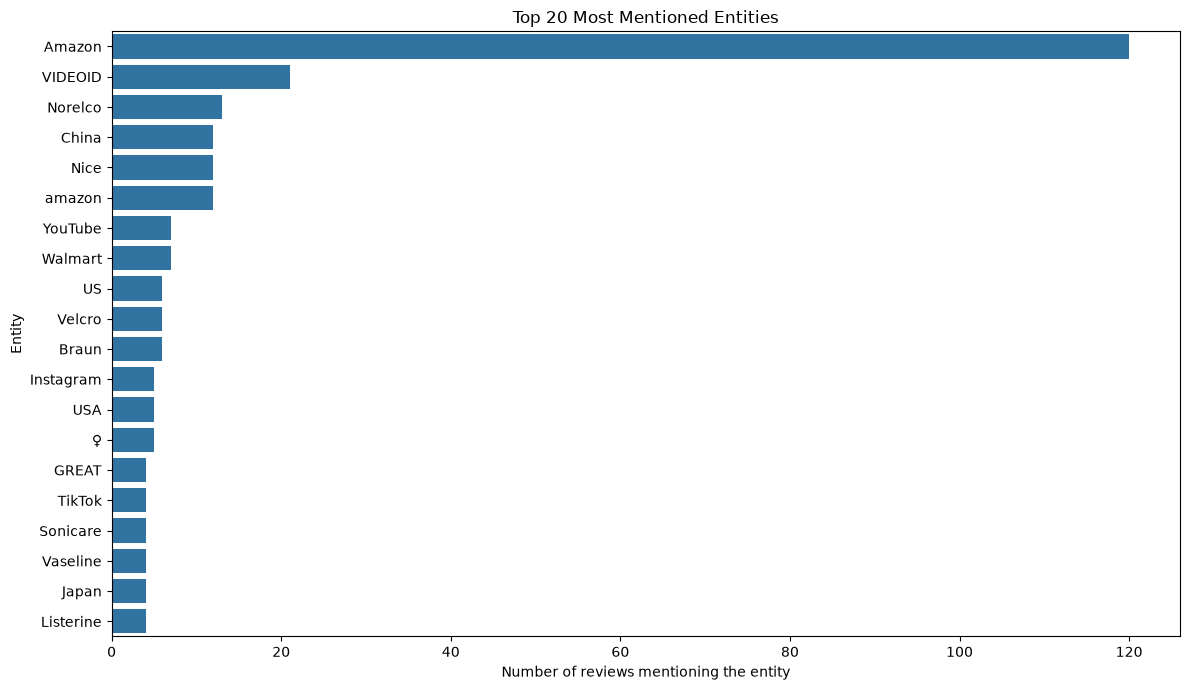

,entity,mentions,mean_sentiment
47,Amazon,120,0.483333
599,VIDEOID,21,0.523810
407,Norelco,13,0.230769
142,China,12,0.166667
402,Nice,12,0.583333
629,amazon,12,0.416667
621,YouTube,7,0.571429
616,Walmart,7,0.285714
589,US,6,0.500000
604,Velcro,6,0.500000


In [43]:
def analyse_entities(data):
    entity_rows = []

    for row_number, row in data.iterrows():
        # Count an entity once per review
        seen_entities = set()

        for entity_name, entity_type in row["entities"]:
            key = (entity_name.lower(), entity_type)

            if key not in seen_entities:
                entity_rows.append({
                    "entity": entity_name,
                    "entity_type": entity_type,
                    "sentiment": row["sentiment"],
                    "review_id": row_number
                })
                seen_entities.add(key)

    entity_df = pd.DataFrame(entity_rows)

    if entity_df.empty:
        print("No matching entities were found by spaCy.")
        return entity_df, pd.DataFrame()

    # Group spelling variants by lowercase entity text
    entity_summary = (
        entity_df.groupby("entity", as_index=False)
        .agg(
            mentions=("review_id", "nunique"),
            mean_sentiment=("sentiment", "mean")
        )
        .sort_values("mentions", ascending=False)
    )

    top_entities = entity_summary.head(20)

    plt.figure(figsize=(12, 7))
    sns.barplot(data=top_entities, x="mentions", y="entity")
    plt.title("Top 20 Most Mentioned Entities")
    plt.xlabel("Number of reviews mentioning the entity")
    plt.ylabel("Entity")
    plt.tight_layout()
    plt.show()

    return entity_df, top_entities


entity_data, top_entities = analyse_entities(df)
display(top_entities)

The mean sentiment is the average of the binary sentiment labels for reviews mentioning each entity.

- A value closer to 1 means the entity is more associated with positive reviews.
- A value closer to 0 means the entity is more associated with negative reviews.

## 7. TF-IDF using POS-filtered tokens

In [44]:
def create_tfidf(data):
    # Join the POS-filtered tokens back into text
    pos_text = data["pos_tokens"].apply(lambda tokens: " ".join(tokens))

    tfidf = TfidfVectorizer(max_features=10000, min_df=2)
    tfidf_matrix = tfidf.fit_transform(pos_text)

    return tfidf, tfidf_matrix, pos_text


tfidf_vectorizer, tfidf_matrix, pos_text = create_tfidf(df)

print("TF-IDF matrix shape:", tfidf_matrix.shape)

TF-IDF matrix shape: (7860, 2907)


## 8. Validate TF-IDF with cosine similarity

I am taking a random sample of around 50 reviews and calculating pairwise cosine similarity.

The sentiment labels are shown on both axes. This makes it easier to visually compare reviews from the same sentiment group and reviews from different groups.

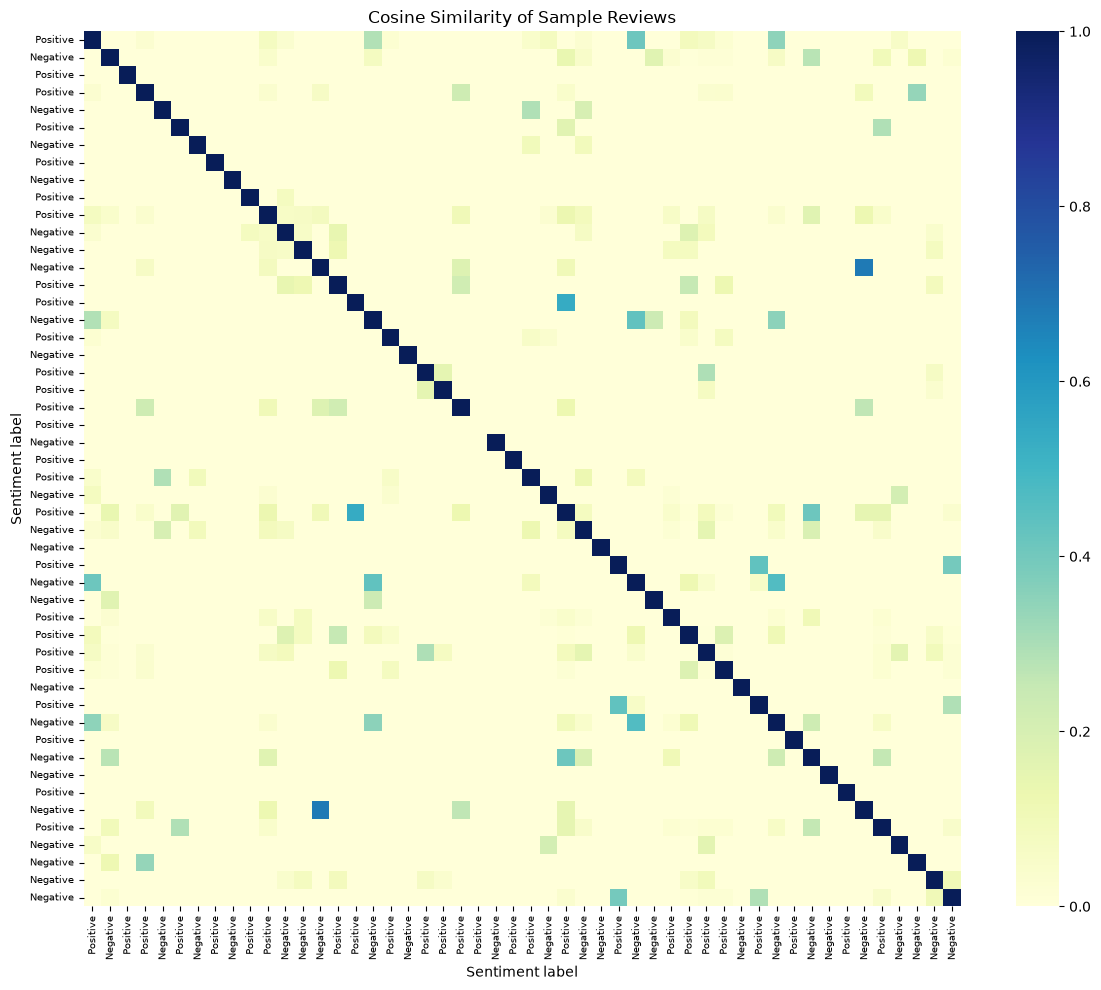

Average same-sentiment similarity: 0.014777379955112422
Average cross-sentiment similarity: 0.012627321422878689


In [45]:
def plot_similarity(data, matrix):
    sample_size = min(50, len(data))
    sample_ids = data.sample(n=sample_size, random_state=RANDOM_STATE).index

    sample_matrix = matrix[sample_ids]
    similarity = cosine_similarity(sample_matrix)
    labels = data.loc[sample_ids, "sentiment"].map({1: "Positive", 0: "Negative"})

    plt.figure(figsize=(12, 10))
    sns.heatmap(
        similarity,
        cmap="YlGnBu",
        xticklabels=labels.tolist(),
        yticklabels=labels.tolist()
    )
    plt.title("Cosine Similarity of Sample Reviews")
    plt.xlabel("Sentiment label")
    plt.ylabel("Sentiment label")
    plt.xticks(rotation=90, fontsize=7)
    plt.yticks(rotation=0, fontsize=7)
    plt.tight_layout()
    plt.show()

    # Compare average similarity for same and different sentiment labels
    label_values = data.loc[sample_ids, "sentiment"].to_numpy()
    same_scores = []
    different_scores = []

    for i in range(sample_size):
        for j in range(i + 1, sample_size):
            if label_values[i] == label_values[j]:
                same_scores.append(similarity[i, j])
            else:
                different_scores.append(similarity[i, j])

    print("Average same-sentiment similarity:", np.mean(same_scores))
    print("Average cross-sentiment similarity:", np.mean(different_scores))


plot_similarity(df, tfidf_matrix)

## 9. Word2Vec embeddings

Word2Vec is trained on the lightly cleaned token stream. I am averaging the word vectors in each review to create one vector for the complete review.

In [46]:
def create_word2vec(data):
    sentences = data["w2v_tokens"].tolist()

    word2vec_model = Word2Vec(
        sentences=sentences,
        vector_size=100,
        window=5,
        min_count=2,
        workers=4,
        sg=1,
        epochs=10,
        seed=RANDOM_STATE
    )

    document_vectors = []

    for words in sentences:
        vectors = [
            word2vec_model.wv[word]
            for word in words
            if word in word2vec_model.wv
        ]

        if vectors:
            document_vectors.append(np.mean(vectors, axis=0))
        else:
            document_vectors.append(np.zeros(100))

    return word2vec_model, np.array(document_vectors)


word2vec_model, word2vec_vectors = create_word2vec(df)

print("Word2Vec document vectors:", word2vec_vectors.shape)

Word2Vec document vectors: (7860, 100)


## 10. Reduce dimensions and plot the embeddings

TF-IDF is first reduced to 50 dimensions using TruncatedSVD. Then PCA is used to show it in 2-D.

The Word2Vec document vectors are also reduced to 2-D using PCA. Both plots are coloured by sentiment.

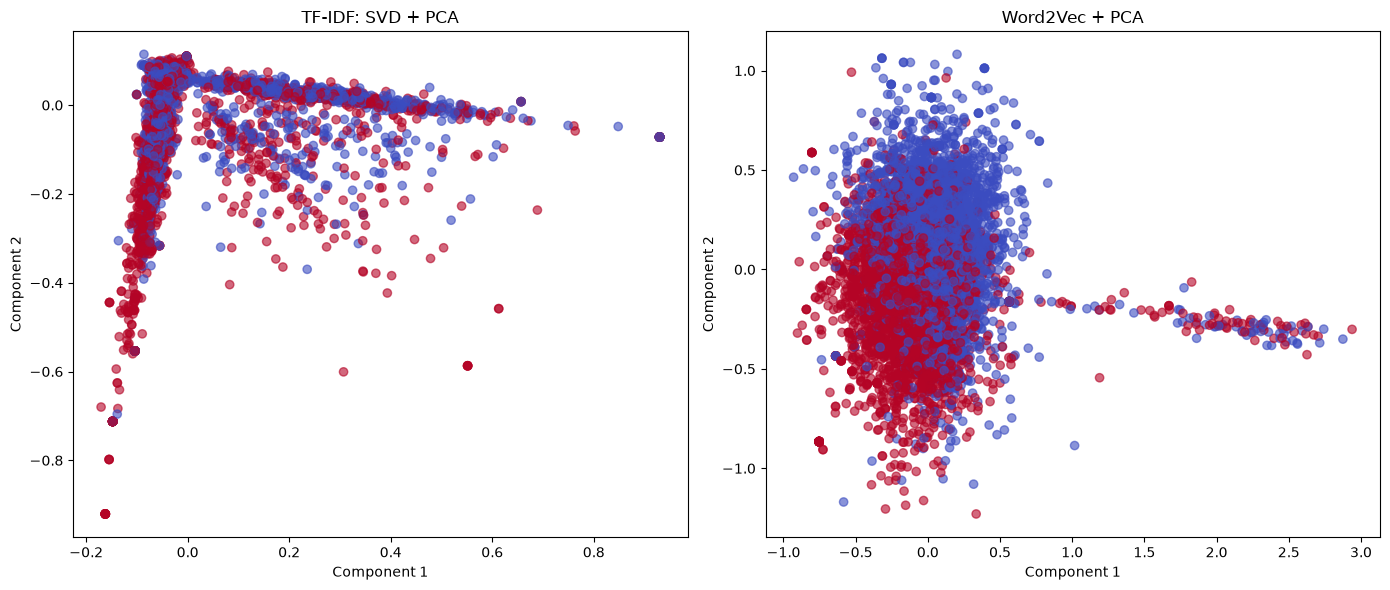

In [47]:
def plot_embeddings(tfidf_matrix, word2vec_vectors, sentiments):
    # Reduce TF-IDF to 50 dimensions first
    svd = TruncatedSVD(n_components=50, random_state=RANDOM_STATE)
    tfidf_50 = svd.fit_transform(tfidf_matrix)

    # PCA for TF-IDF
    tfidf_2d = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(tfidf_50)

    # PCA for Word2Vec
    w2v_2d = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(word2vec_vectors)

    fig, axes = plt.subplots(1, 2, figsize=(14, 6))

    axes[0].scatter(
        tfidf_2d[:, 0], tfidf_2d[:, 1],
        c=sentiments, cmap="coolwarm", alpha=0.6
    )
    axes[0].set_title("TF-IDF: SVD + PCA")
    axes[0].set_xlabel("Component 1")
    axes[0].set_ylabel("Component 2")

    axes[1].scatter(
        w2v_2d[:, 0], w2v_2d[:, 1],
        c=sentiments, cmap="coolwarm", alpha=0.6
    )
    axes[1].set_title("Word2Vec + PCA")
    axes[1].set_xlabel("Component 1")
    axes[1].set_ylabel("Component 2")

    plt.tight_layout()
    plt.show()


plot_embeddings(tfidf_matrix, word2vec_vectors, df["sentiment"].to_numpy())

## 11. Topic modelling using LDA

I am using the POS-filtered tokens to build a Gensim Dictionary and Bag-of-Words corpus.

I will train LDA models for 5, 7 and 10 topics. The coherence score (`c_v`) will help me select the best model.

In [48]:
def train_lda_models(data):
    token_lists = data["pos_tokens"].tolist()

    dictionary = Dictionary(token_lists)
    dictionary.filter_extremes(no_below=2, no_above=0.95)

    corpus = [dictionary.doc2bow(tokens) for tokens in token_lists]

    topic_models = {}
    coherence_scores = []

    for k in [5, 7, 10]:
        print("Training LDA with", k, "topics")

        model = LdaModel(
            corpus=corpus,
            id2word=dictionary,
            num_topics=k,
            random_state=RANDOM_STATE,
            passes=10,
            alpha="auto",
            eta="auto"
        )

        coherence_model = CoherenceModel(
            model=model,
            texts=token_lists,
            dictionary=dictionary,
            coherence="c_v"
        )

        coherence = coherence_model.get_coherence()
        topic_models[k] = model
        coherence_scores.append({"Number of Topics": k, "Coherence": coherence})

    coherence_df = pd.DataFrame(coherence_scores)
    best_k = coherence_df.loc[coherence_df["Coherence"].idxmax(), "Number of Topics"]
    best_model = topic_models[int(best_k)]

    return dictionary, corpus, topic_models, coherence_df, best_model, int(best_k)


dictionary, corpus, lda_models, coherence_df, best_lda, best_k = train_lda_models(df)

display(coherence_df)
print("Best number of topics:", best_k)

Training LDA with 5 topics
Training LDA with 7 topics
Training LDA with 10 topics


,Number of Topics,Coherence
0,5,0.484279
1,7,0.461318
2,10,0.435729


Best number of topics: 5


## 12. Compare LDA coherence scores

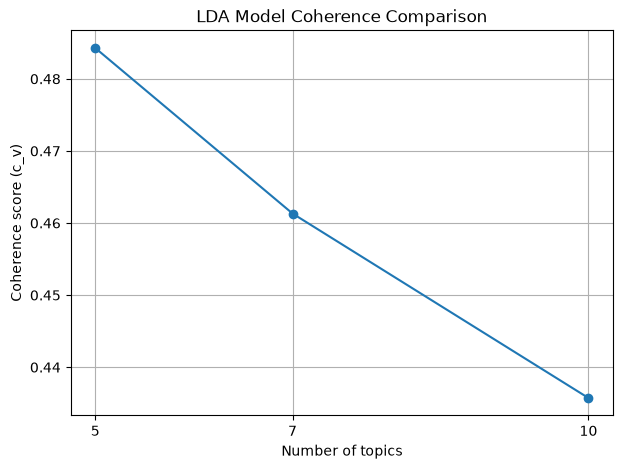

In [49]:
plt.figure(figsize=(7, 5))
plt.plot(
    coherence_df["Number of Topics"],
    coherence_df["Coherence"],
    marker="o"
)
plt.xlabel("Number of topics")
plt.ylabel("Coherence score (c_v)")
plt.title("LDA Model Coherence Comparison")
plt.xticks([5, 7, 10])
plt.grid()
plt.show()

## 13. View topics and word clouds

The words shown for each topic help me understand what customers are discussing. I will use these words to give each topic a simple human-readable label after checking the output.

Topic 1: product, skin, great, good, smell, face, scent, oil, time, mask, review, soft, year, dry, soap
Topic 2: good, quality, great, lash, easy, price, color, time, makeup, light, perfect, eye, brand, nice, natural
Topic 3: hair, wig, good, thin, thick, product, shampoo, great, quality, soft, long, head, clip, nice, conditioner
Topic 4: brush, small, bottle, money, great, size, nice, daughter, cute, bag, time, little, big, hand, plastic
Topic 5: color, nail, product, day, time, polish, week, skin, eye, bad, little, gel, light, good, tooth


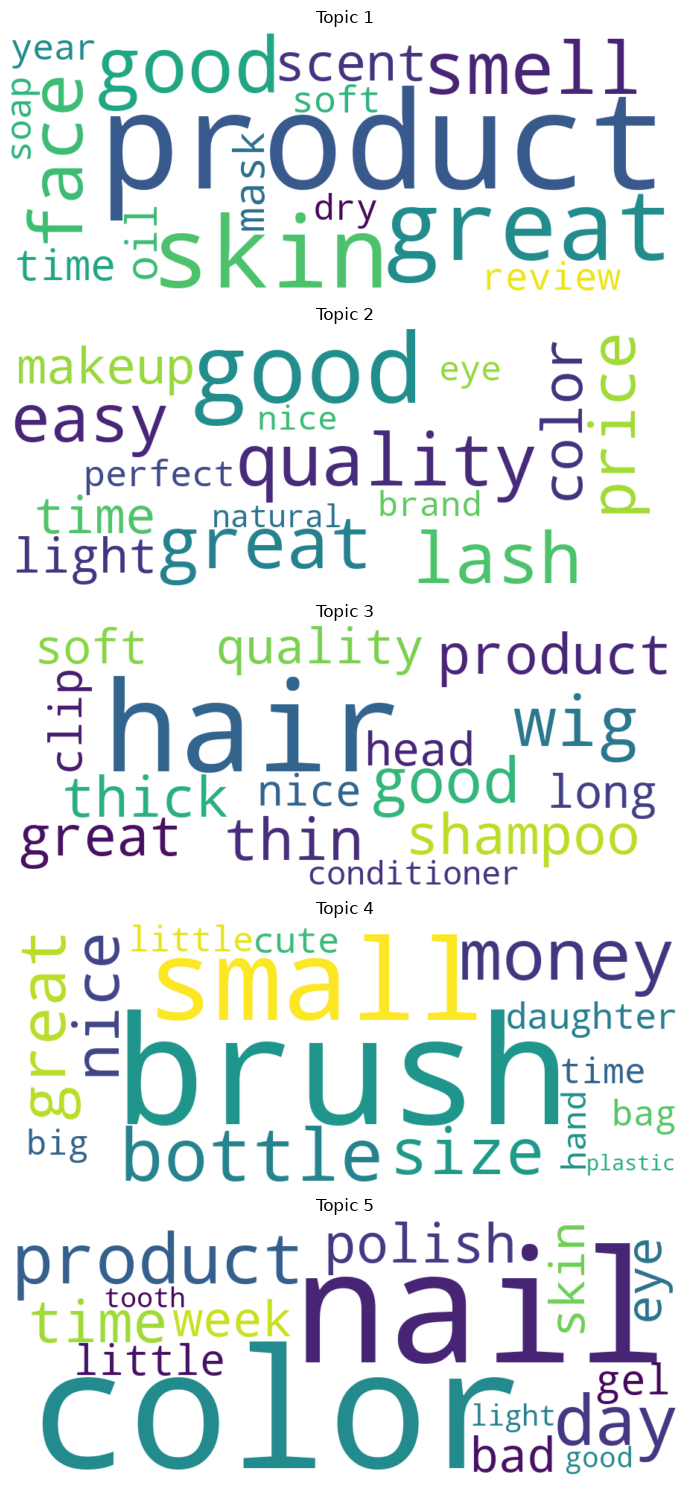

In [50]:
def show_topics_and_wordclouds(model, number_of_topics):
    topic_words = {}

    fig, axes = plt.subplots(
        number_of_topics, 1,
        figsize=(10, number_of_topics * 3)
    )

    if number_of_topics == 1:
        axes = [axes]

    for topic_id in range(number_of_topics):
        words = dict(model.show_topic(topic_id, topn=15))
        topic_words[topic_id] = words

        print(f"Topic {topic_id + 1}:", ", ".join(words.keys()))

        cloud = WordCloud(
            width=900,
            height=350,
            background_color="white"
        ).generate_from_frequencies(words)

        axes[topic_id].imshow(cloud, interpolation="bilinear")
        axes[topic_id].axis("off")
        axes[topic_id].set_title(f"Topic {topic_id + 1}")

    plt.tight_layout()
    plt.show()

    return topic_words


topic_words = show_topics_and_wordclouds(best_lda, best_k)

## 14. Give topics human-readable labels

After checking the top words printed above, I can update these labels to describe the actual topics found in my dataset. The default labels below are neutral placeholders and should be edited based on the topic words.

In [51]:
# Update these labels after looking at the words printed for each topic
topic_labels = {
    topic_id: f"Topic {topic_id + 1}"
    for topic_id in range(best_k)
}

print(topic_labels)

{0: 'Topic 1', 1: 'Topic 2', 2: 'Topic 3', 3: 'Topic 4', 4: 'Topic 5'}


## 15. Assign a dominant topic to each review

For each review, I am taking the topic with the highest probability. Then I calculate the percentage of positive and negative reviews in each topic.

In [52]:
def analyse_topic_sentiment(data, model, corpus, topic_labels):
    dominant_topics = []

    for bow in corpus:
        topic_probs = model.get_document_topics(bow, minimum_probability=0)
        dominant_topic = max(topic_probs, key=lambda item: item[1])[0]
        dominant_topics.append(dominant_topic)

    result = data[["sentiment"]].copy()
    result["topic_id"] = dominant_topics
    result["topic_label"] = result["topic_id"].map(topic_labels)

    topic_sentiment = pd.crosstab(
        result["topic_label"],
        result["sentiment"],
        normalize="index"
    ) * 100

    topic_sentiment = topic_sentiment.rename(
        columns={0: "Negative %", 1: "Positive %"}
    )

    return result, topic_sentiment


topic_results, topic_sentiment = analyse_topic_sentiment(
    df, best_lda, corpus, topic_labels
)

display(topic_sentiment.round(2))

sentiment,Negative %,Positive %
topic_label,,
Topic 1,41.29,58.71
Topic 2,38.75,61.25
Topic 3,56.31,43.69
Topic 4,57.86,42.14
Topic 5,64.36,35.64


## 16. Train sentiment classification models

I am splitting the data into 80% training and 20% testing data using `random_state=42`.

The TF-IDF vectorizer is fitted only on the training reviews. The same fitted vectorizer is then used to transform the test reviews.

In [53]:
def prepare_classifier_data(data):
    X_train_text, X_test_text, y_train, y_test = train_test_split(
        data["pos_tokens"].apply(lambda tokens: " ".join(tokens)),
        data["sentiment"],
        test_size=0.20,
        random_state=42,
        stratify=data["sentiment"]
    )

    vectorizer = TfidfVectorizer(max_features=10000, min_df=2)
    X_train = vectorizer.fit_transform(X_train_text)
    X_test = vectorizer.transform(X_test_text)

    return vectorizer, X_train, X_test, y_train, y_test


classifier_vectorizer, X_train, X_test, y_train, y_test = prepare_classifier_data(df)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])

Training rows: 6288
Testing rows: 1572


## 17. Train and compare the three classifiers

In [54]:
def train_classifiers(X_train, X_test, y_train, y_test):
    models = {
        "MultinomialNB": MultinomialNB(),
        "BernoulliNB": BernoulliNB(),
        "Logistic Regression": LogisticRegression(max_iter=500)
    }

    results = []
    roc_data = {}
    trained_models = {}

    for name, model in models.items():
        print("Training", name)
        model.fit(X_train, y_train)

        predictions = model.predict(X_test)
        scores = model.predict_proba(X_test)[:, 1]

        results.append({
            "Model": name,
            "Accuracy": accuracy_score(y_test, predictions),
            "Precision": precision_score(y_test, predictions, zero_division=0),
            "Recall": recall_score(y_test, predictions, zero_division=0),
            "F1 Score": f1_score(y_test, predictions, zero_division=0),
            "AUC": roc_auc_score(y_test, scores)
        })

        roc_data[name] = roc_curve(y_test, scores)
        trained_models[name] = model

    results_df = pd.DataFrame(results).sort_values("AUC", ascending=False)

    return results_df, roc_data, trained_models


classifier_results, roc_data, trained_models = train_classifiers(
    X_train, X_test, y_train, y_test
)

display(classifier_results.round(4))

Training MultinomialNB
Training BernoulliNB
Training Logistic Regression


,Model,Accuracy,Precision,Recall,F1 Score,AUC
0,MultinomialNB,0.7430,0.7480,0.7229,0.7353,0.8306
1,BernoulliNB,0.7513,0.7685,0.7101,0.7381,0.8283
2,Logistic Regression,0.7316,0.7514,0.6817,0.7149,0.8257


## 18. Plot ROC curves for all classifiers

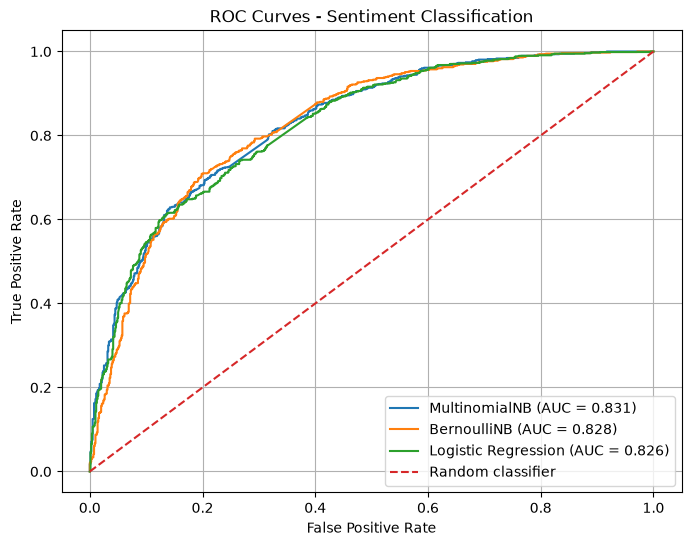

In [55]:
plt.figure(figsize=(8, 6))

for name, (fpr, tpr, thresholds) in roc_data.items():
    auc_value = classifier_results.loc[
        classifier_results["Model"] == name, "AUC"
    ].iloc[0]

    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc_value:.3f})")

plt.plot([0, 1], [0, 1], "--", label="Random classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves - Sentiment Classification")
plt.legend()
plt.grid()
plt.show()

## 19. Evaluate the best classifier

Best model: MultinomialNB
              precision    recall  f1-score   support

    Negative       0.74      0.76      0.75       796
    Positive       0.75      0.72      0.74       776

    accuracy                           0.74      1572
   macro avg       0.74      0.74      0.74      1572
weighted avg       0.74      0.74      0.74      1572



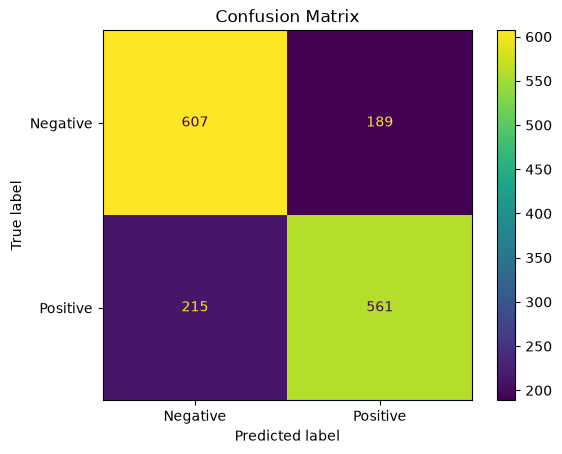

In [56]:
best_model_name = classifier_results.iloc[0]["Model"]
best_classifier = trained_models[best_model_name]
best_predictions = best_classifier.predict(X_test)

print("Best model:", best_model_name)
print(classification_report(
    y_test,
    best_predictions,
    target_names=["Negative", "Positive"]
))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    best_predictions,
    display_labels=["Negative", "Positive"]
)
plt.title("Confusion Matrix")
plt.show()

## 20. Save the main results

I am saving the classifier comparison, top entities and topic sentiment table so that I can use the actual results while preparing the final PDF report.

In [57]:
classifier_results.to_csv("Results_classifier_comparison.csv", index=False)
top_entities.to_csv("Results_top_ner_entities.csv", index=False)
topic_sentiment.to_csv("Results_topic_sentiment_split.csv")

print("Result files saved successfully.")

Result files saved successfully.


## 21. Conclusion

In this assignment, I analysed Amazon Beauty product reviews using NLP.

I used two token streams because TF-IDF and LDA need nouns and adjectives to find product-related terms and topics, while Word2Vec can learn context from a wider range of useful words.

I also used spaCy NER to find frequently mentioned entities and checked the sentiment of reviews mentioning them. TF-IDF and Word2Vec were used to create review representations, and PCA plots helped me compare their patterns.

For topic modelling, I trained LDA models with 5, 7 and 10 topics and selected the model with the highest coherence score. Finally, I trained Multinomial Naive Bayes, Bernoulli Naive Bayes and Logistic Regression to classify review sentiment.